In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (
    train_test_split,
    TimeSeriesSplit,
    GridSearchCV
)
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay,
    PrecisionRecallDisplay
)


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks


import shap
from sklearn.inspection import permutation_importance

In [2]:

path = '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/'

circuits = pd.read_csv(path + 'circuits.csv', na_values=['\\N'])
constructors = pd.read_csv(path + 'constructors.csv', na_values=['\\N'])
constructor_results = pd.read_csv(path + 'constructor_results.csv', na_values=['\\N'])
constructor_standings = pd.read_csv(path + 'constructor_standings.csv', na_values=['\\N'])
drivers = pd.read_csv(path + 'drivers.csv', na_values=['\\N'])
driver_standings = pd.read_csv(path + 'driver_standings.csv', na_values=['\\N'])
races = pd.read_csv(path + 'races.csv', na_values=['\\N'])
results = pd.read_csv(path + 'results.csv', na_values=['\\N'])
qualifying = pd.read_csv(path + 'qualifying.csv', na_values=['\\N'])
lap_times = pd.read_csv(path + 'lap_times.csv', na_values=['\\N'])
pit_stops = pd.read_csv(path + 'pit_stops.csv', na_values=['\\N'])
sprint_results = pd.read_csv(path + 'sprint_results.csv', na_values=['\\N'])
seasons = pd.read_csv(path + 'seasons.csv', na_values=['\\N'])
status = pd.read_csv(path + 'status.csv', na_values=['\\N'])





In [3]:
circuits.head()


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


In [4]:
circuits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


In [5]:
constructors.head()

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


In [6]:
constructors.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   constructorId   212 non-null    int64 
 1   constructorRef  212 non-null    object
 2   name            212 non-null    object
 3   nationality     212 non-null    object
 4   url             212 non-null    object
dtypes: int64(1), object(4)
memory usage: 8.4+ KB


In [7]:
constructor_results.head()

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


In [8]:
constructor_results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                17 non-null     object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB


In [9]:
constructor_standings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  object 
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 732.4+ KB


In [10]:
constructor_standings.head()

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


In [11]:
drivers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   driverId     861 non-null    int64  
 1   driverRef    861 non-null    object 
 2   number       59 non-null     float64
 3   code         104 non-null    object 
 4   forename     861 non-null    object 
 5   surname      861 non-null    object 
 6   dob          861 non-null    object 
 7   nationality  861 non-null    object 
 8   url          861 non-null    object 
dtypes: float64(1), int64(1), object(7)
memory usage: 60.7+ KB


In [12]:
drivers.head()

,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44.0,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,NaN,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6.0,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14.0,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,NaN,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen


In [13]:
driver_standings.head()

,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


In [14]:
driver_standings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34863 entries, 0 to 34862
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   driverStandingsId  34863 non-null  int64  
 1   raceId             34863 non-null  int64  
 2   driverId           34863 non-null  int64  
 3   points             34863 non-null  float64
 4   position           34863 non-null  int64  
 5   positionText       34863 non-null  object 
 6   wins               34863 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 1.9+ MB


In [15]:
races.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1125 entries, 0 to 1124
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   raceId       1125 non-null   int64 
 1   year         1125 non-null   int64 
 2   round        1125 non-null   int64 
 3   circuitId    1125 non-null   int64 
 4   name         1125 non-null   object
 5   date         1125 non-null   object
 6   time         394 non-null    object
 7   url          1125 non-null   object
 8   fp1_date     90 non-null     object
 9   fp1_time     68 non-null     object
 10  fp2_date     90 non-null     object
 11  fp2_time     68 non-null     object
 12  fp3_date     72 non-null     object
 13  fp3_time     53 non-null     object
 14  quali_date   90 non-null     object
 15  quali_time   68 non-null     object
 16  sprint_date  18 non-null     object
 17  sprint_time  15 non-null     object
dtypes: int64(4), object(14)
memory usage: 158.3+ KB


In [16]:
races.head()

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


In [18]:
results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   object 
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpeed  8252 non-null   float64
 17  statusId    

In [19]:
qualifying.head()

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [20]:
qualifying.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10494 entries, 0 to 10493
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   qualifyId      10494 non-null  int64 
 1   raceId         10494 non-null  int64 
 2   driverId       10494 non-null  int64 
 3   constructorId  10494 non-null  int64 
 4   number         10494 non-null  int64 
 5   position       10494 non-null  int64 
 6   q1             10338 non-null  object
 7   q2             5847 non-null   object
 8   q3             3629 non-null   object
dtypes: int64(6), object(3)
memory usage: 738.0+ KB


In [21]:
lap_times.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   raceId        589081 non-null  int64 
 1   driverId      589081 non-null  int64 
 2   lap           589081 non-null  int64 
 3   position      589081 non-null  int64 
 4   time          589081 non-null  object
 5   milliseconds  589081 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 27.0+ MB


In [22]:
lap_times.head()

,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342


In [23]:
pit_stops.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   raceId        11371 non-null  int64 
 1   driverId      11371 non-null  int64 
 2   stop          11371 non-null  int64 
 3   lap           11371 non-null  int64 
 4   time          11371 non-null  object
 5   duration      11371 non-null  object
 6   milliseconds  11371 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 622.0+ KB


In [24]:
pit_stops.head() 

,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842


In [25]:
sprint_results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1.0,1,1,3,17,25:38.426,1538426.0,14.0,1:30.013,1
1,2,1061,1,131,44,1,2.0,2,2,2,17,+1.430,1539856.0,17.0,1:29.937,1
2,3,1061,822,131,77,3,3.0,3,3,1,17,+7.502,1545928.0,17.0,1:29.958,1
3,4,1061,844,6,16,4,4.0,4,4,0,17,+11.278,1549704.0,16.0,1:30.163,1
4,5,1061,846,1,4,6,5.0,5,5,0,17,+24.111,1562537.0,16.0,1:30.566,1


In [26]:
sprint_results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   resultId        360 non-null    int64  
 1   raceId          360 non-null    int64  
 2   driverId        360 non-null    int64  
 3   constructorId   360 non-null    int64  
 4   number          360 non-null    int64  
 5   grid            360 non-null    int64  
 6   position        345 non-null    float64
 7   positionText    360 non-null    object 
 8   positionOrder   360 non-null    int64  
 9   points          360 non-null    int64  
 10  laps            360 non-null    int64  
 11  time            340 non-null    object 
 12  milliseconds    340 non-null    float64
 13  fastestLap      351 non-null    float64
 14  fastestLapTime  351 non-null    object 
 15  statusId        360 non-null    int64  
dtypes: float64(3), int64(10), object(3)
memory usage: 45.1+ KB


In [27]:
seasons.head()

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


In [28]:
seasons.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   year    75 non-null     int64 
 1   url     75 non-null     object
dtypes: int64(1), object(1)
memory usage: 1.3+ KB


In [29]:
status.head()

,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


In [30]:
status.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   statusId  139 non-null    int64 
 1   status    139 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.3+ KB


In [31]:
# Part 1: Exploratory Data Analysis (EDA)

## 1.1 Initial Dataset Overview

# Before performing data cleaning, we examine the structure and size of the 14 relational Formula 1 datasets. This initial exploration helps identify differences in table sizes and provides an overview of the available data.

# Store the datasets in a dictionary for easier exploration
datasets = {
    "circuits": circuits,
    "constructors": constructors,
    "constructor_results": constructor_results,
    "constructor_standings": constructor_standings,
    "drivers": drivers,
    "driver_standings": driver_standings,
    "races": races,
    "results": results,
    "qualifying": qualifying,
    "lap_times": lap_times,
    "pit_stops": pit_stops,
    "sprint_results": sprint_results,
    "seasons": seasons,
    "status": status
}

# Create a summary of each table
dataset_overview = pd.DataFrame([
    {
        "Table": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isna().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    }
    for name, df in datasets.items()
])

display(dataset_overview)


,Table,Rows,Columns,Missing Values,Duplicate Rows
0,circuits,77,9,0,0
1,constructors,212,5,0,0
2,constructor_results,12625,5,12608,0
3,constructor_standings,13391,7,0,0
4,drivers,861,9,1559,0
5,driver_standings,34863,7,0,0
6,races,1125,18,11349,0
7,results,26759,18,122887,0
8,qualifying,10494,9,11668,0
9,lap_times,589081,6,0,0


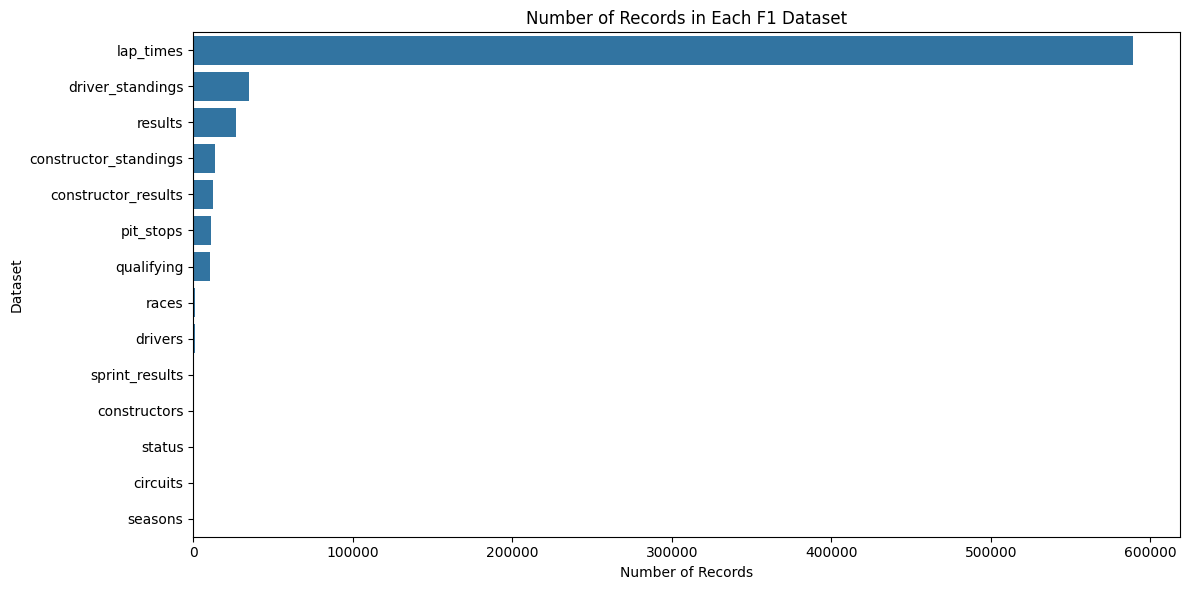

In [32]:
### Initial EDA Findings
# The dataset consists of 14 relational tables with significantly different sizes.
# The `lap_times` table contains the largest number of records (589,081), reflecting the multiple lap observations recorded for each driver during a race. In contrast, smaller reference tables, such as `seasons` and `circuits`, contain relatively few records.
# Several tables contain substantial missing data. In particular, `results`, `qualifying`, and `races` have high numbers of missing values. These require further investigation to distinguish historical data limitations, structurally unavailable measurements, and values requiring cleaning.
# No exact duplicate rows were detected across the 14 tables. However, additional primary-key, foreign-key, and driver–race uniqueness checks are still required.

plt.figure(figsize=(12, 6))

sns.barplot(
    data=dataset_overview.sort_values("Rows", ascending=False),
    x="Rows",
    y="Table"
)

plt.title("Number of Records in Each F1 Dataset")
plt.xlabel("Number of Records")
plt.ylabel("Dataset")
plt.tight_layout()
plt.show()


In [33]:

## 1.2 Missing Value Analysis
# We examine the proportion of missing values in each dataset before applying cleaning operations.

# Calculate missing-value statistics before cleaning

missing_summary = pd.DataFrame([
    {
        "Table": name,
        "Total Cells": df.size,
        "Missing Values": df.isna().sum().sum(),
        "Missing Percentage": (
            df.isna().sum().sum() / df.size * 100
            if df.size > 0 else 0
        )
    }
    for name, df in datasets.items()
])

missing_summary = missing_summary.sort_values(
    "Missing Percentage", ascending=False
)

display(missing_summary.round(2))


,Table,Total Cells,Missing Values,Missing Percentage
6,races,20250,11349,56.04
7,results,481662,122887,25.51
4,drivers,7749,1559,20.12
2,constructor_results,63125,12608,19.97
8,qualifying,94446,11668,12.35
11,sprint_results,5760,73,1.27
5,driver_standings,244041,0,0.00
3,constructor_standings,93737,0,0.00
0,circuits,693,0,0.00
1,constructors,1060,0,0.00


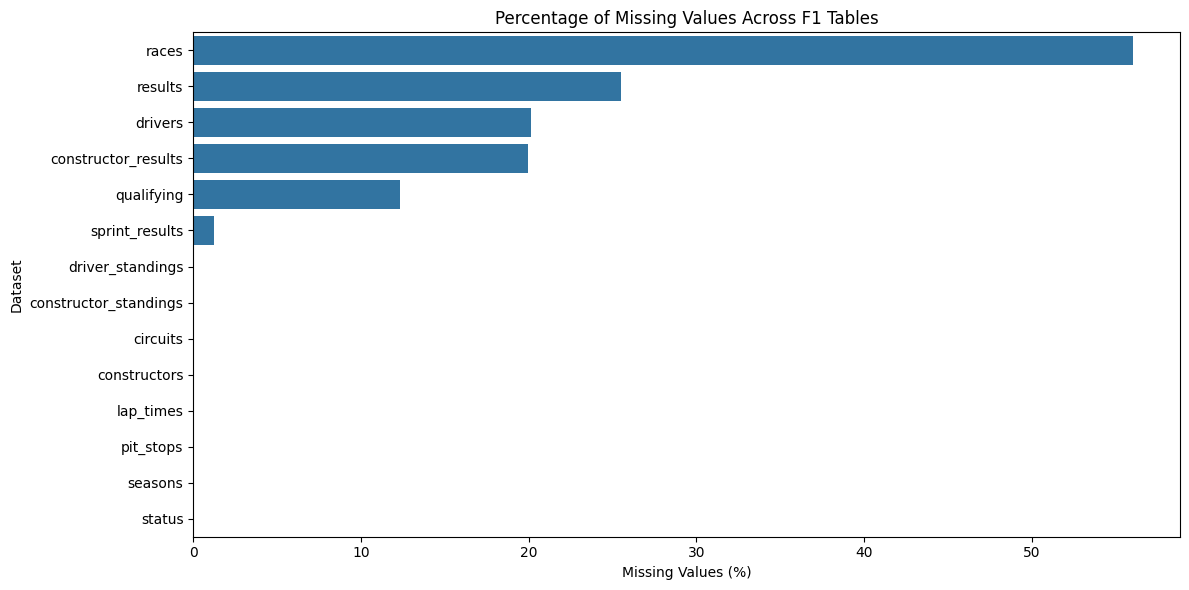

In [34]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_summary,
    x="Missing Percentage",
    y="Table"
)

plt.title("Percentage of Missing Values Across F1 Tables")
plt.xlabel("Missing Values (%)")
plt.ylabel("Dataset")

plt.tight_layout()
plt.show()


In [35]:
### Missing Value Analysis: Findings
# The missing-value analysis revealed substantial differences in data completeness across the 14 Formula 1 tables.
# The `races` table has the highest overall missingness (56.04%), followed by `results` (25.51%), `drivers` (20.12%), `constructor_results` (19.97%), and `qualifying` (12.35%). Eight tables contain no missing values.
# A closer examination of `results` revealed particularly high missingness in timing-related attributes. The `time` and `milliseconds` columns each have 71.30% missing values, while fastest-lap attributes have approximately 68–69% missingness.
# These missing values may reflect historical limitations in data collection, race retirements, or measurements that were not applicable to certain records. Their causes require further investigation before cleaning decisions are made.
# Importantly, the `positionOrder` column contains no missing values and can be used to construct the binary podium prediction target.
# Therefore, rows should not be removed solely because post-race timing measurements or official finishing positions are unavailable. Missing values will be handled according to column meaning, historical coverage, and their relevance to the prediction task.

# Missing values by column for the results table

results_missing = pd.DataFrame({
    "Missing Count": results.isna().sum(),
    "Missing Percentage": results.isna().mean() * 100
})

results_missing = results_missing[
    results_missing["Missing Count"] > 0
].sort_values("Missing Percentage", ascending=False)

display(results_missing.round(2))


,Missing Count,Missing Percentage
milliseconds,19079,71.30
time,19079,71.30
fastestLapTime,18507,69.16
fastestLap,18507,69.16
fastestLapSpeed,18507,69.16
rank,18249,68.20
position,10953,40.93
number,6,0.02


In [36]:

## 1.3 Historical Qualifying Data Coverage
# We investigate how qualifying data availability varies across Formula 1 seasons. This helps identify historical coverage limitations and their potential impact on feature engineering.

# Identify races with qualifying records

qualifying_coverage = races[
    ["raceId", "year"]
].merge(
    qualifying[["raceId", "driverId"]],
    on="raceId",
    how="left"
)

# Calculate the proportion of race entrants
# who have a qualifying record in each season

race_entries = results[
    ["raceId", "driverId"]
].drop_duplicates()

race_entries = race_entries.merge(
    races[["raceId", "year"]],
    on="raceId",
    how="left"
)

qualifying_keys = qualifying[
    ["raceId", "driverId"]
].drop_duplicates()

race_entries = race_entries.merge(
    qualifying_keys.assign(has_qualifying=1),
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

race_entries["has_qualifying"] = (
    race_entries["has_qualifying"]
    .fillna(0)
)

coverage_by_year = (
    race_entries.groupby("year")["has_qualifying"]
    .mean()
    .mul(100)
    .reset_index(name="Coverage Percentage")
)

display(coverage_by_year)


,year,Coverage Percentage
0,1950,0.000000
1,1951,0.000000
2,1952,0.000000
3,1953,0.000000
4,1954,0.000000
...,...,...
70,2020,100.000000
71,2021,99.772727
72,2022,100.000000
73,2023,100.000000


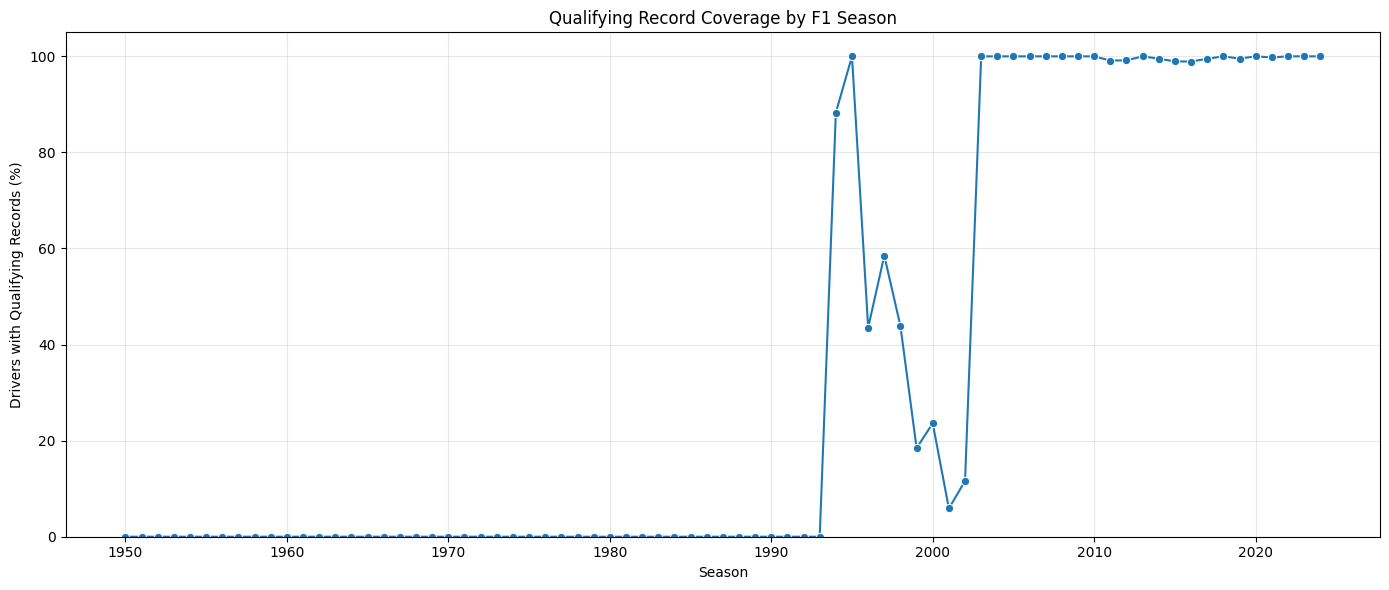

In [37]:
### Historical Qualifying Coverage: Findings
# The analysis reveals substantial historical variation in qualifying data availability.
# Between 1950 and 1993, no matching qualifying records were found in the dataset. From 1994 to 2002, qualifying record coverage fluctuated considerably, indicating inconsistent historical availability.
# From 2003 onward, coverage becomes approximately complete, with nearly 100% of driver–race entries having matching qualifying records.
# These results demonstrate historical qualifying-coverage drift, an important limitation for developing predictive models across multiple Formula 1 eras.
# Consequently, qualifying-based features cannot be treated as uniformly available throughout the dataset. Starting-grid position may provide an alternative source of pre-race information for older seasons, while qualifying-specific attributes require additional missing-data analysis.
# The final feature-engineering strategy must account for these historical differences without using information unavailable before the race.

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=coverage_by_year,
    x="year",
    y="Coverage Percentage",
    marker="o"
)

plt.title("Qualifying Record Coverage by F1 Season")
plt.xlabel("Season")
plt.ylabel("Drivers with Qualifying Records (%)")

plt.ylim(0, 105)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [38]:

## 1.4 Data Integrity Auditing
### Primary-Key Validation
# Before cleaning and joining the relational tables, we validate the uniqueness and completeness of their primary keys. This helps identify potential data-integrity issues that could affect subsequent analysis.


# Candidate primary keys for the 14 F1 tables

primary_keys = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "qualifying": ["qualifyId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "sprint_results": ["resultId"],
    "seasons": ["year"],
    "status": ["statusId"]
}

pk_audit = []

for name, key_columns in primary_keys.items():
    df = datasets[name]

    null_keys = df[key_columns].isna().any(axis=1).sum()
    duplicate_keys = df.duplicated(
        subset=key_columns
    ).sum()

    pk_audit.append({
        "Table": name,
        "Primary Key": ", ".join(key_columns),
        "Null Keys": null_keys,
        "Duplicate Keys": duplicate_keys,
        "Valid": null_keys == 0 and duplicate_keys == 0
    })

pk_audit_df = pd.DataFrame(pk_audit)

display(pk_audit_df)


### Primary-Key Audit Findings
# The primary-key validation was performed across all 14 relational tables.
# All tables passed the audit, with zero null or duplicate values in their candidate primary keys.
# For tables containing repeated observations, composite keys were used. In particular, `lap_times` was validated using (`raceId`, `driverId`, `lap`), while `pit_stops` was validated using (`raceId`, `driverId`, `stop`).
# These results confirm that the tested keys uniquely identify the records in their respective tables.
# However, primary-key validity does not guarantee referential integrity. Foreign-key relationships must also be examined to identify records referencing nonexistent entities.


,Table,Primary Key,Null Keys,Duplicate Keys,Valid
0,circuits,circuitId,0,0,True
1,constructors,constructorId,0,0,True
2,constructor_results,constructorResultsId,0,0,True
3,constructor_standings,constructorStandingsId,0,0,True
4,drivers,driverId,0,0,True
5,driver_standings,driverStandingsId,0,0,True
6,races,raceId,0,0,True
7,results,resultId,0,0,True
8,qualifying,qualifyId,0,0,True
9,lap_times,"raceId, driverId, lap",0,0,True


In [39]:

### Foreign-Key Validation
# Foreign-key integrity is checked to verify that references between the relational tables are consistent.
# For each relationship, we compare the foreign-key values in the child table against the corresponding primary-key values in the parent table.
# This helps identify orphan records that could cause missing information or unexpected behavior during table joins.


# Foreign-key relationships:
# (child table, foreign key, parent table, parent key)

foreign_keys = [
    ("races", "circuitId", "circuits", "circuitId"),

    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),

    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),

    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),

    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),

    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),

    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),

    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),

    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),

    ("races", "year", "seasons", "year")
]

fk_audit = []

for child, fk, parent, pk in foreign_keys:

    child_values = datasets[child][fk]
    parent_values = datasets[parent][pk]

    missing_fk = child_values.isna().sum()

    invalid_fk = (
        child_values.notna()
        & ~child_values.isin(parent_values.dropna())
    ).sum()

    fk_audit.append({
        "Child Table": child,
        "Foreign Key": fk,
        "Parent Table": parent,
        "Null References": missing_fk,
        "Invalid References": invalid_fk,
        "Valid": invalid_fk == 0
    })

fk_audit_df = pd.DataFrame(fk_audit)

display(fk_audit_df)

print(
    "Relationships with invalid references:",
    (fk_audit_df["Invalid References"] > 0).sum()
)


### Foreign-Key Audit Findings
# Foreign-key validation was performed across 22 relationships connecting the Formula 1 relational tables.
# All 22 relationships passed the integrity checks, with zero null references and zero invalid references.
# These findings indicate that the tested relationships are consistent and that all foreign-key values successfully reference existing records in their corresponding parent tables.
# Although the tested relationships satisfy referential integrity requirements, additional checks are needed to identify duplicated driver–race combinations and determine whether historical shared-drive records violate the required modeling-table granularity.


,Child Table,Foreign Key,Parent Table,Null References,Invalid References,Valid
0,races,circuitId,circuits,0,0,True
1,results,raceId,races,0,0,True
2,results,driverId,drivers,0,0,True
3,results,constructorId,constructors,0,0,True
4,results,statusId,status,0,0,True
5,qualifying,raceId,races,0,0,True
6,qualifying,driverId,drivers,0,0,True
7,qualifying,constructorId,constructors,0,0,True
8,driver_standings,raceId,races,0,0,True
9,driver_standings,driverId,drivers,0,0,True


Relationships with invalid references: 0


In [40]:

## 1.5 Driver–Race Duplicate Investigation
# The prediction task requires one observation for each driver participating in a race.
# Although `resultId` is unique, the combination of `raceId` and `driverId` may not be unique because of historical shared-drive practices.
# We investigate these duplicate combinations before selecting and justifying a deduplication strategy.


# Identify driver-race combinations appearing more than once

driver_race_counts = (
    results.groupby(["raceId", "driverId"])
    .size()
    .reset_index(name="record_count")
)

duplicate_driver_races = driver_race_counts[
    driver_race_counts["record_count"] > 1
].copy()

print(
    "Total result records:",
    len(results)
)

print(
    "Unique driver-race combinations:",
    len(driver_race_counts)
)

print(
    "Duplicate driver-race combinations:",
    len(duplicate_driver_races)
)

print(
    "Extra rows beyond one per driver-race:",
    len(results) - len(driver_race_counts)
)

display(duplicate_driver_races.head(20))


Total result records: 26759
Unique driver-race combinations: 26668
Duplicate driver-race combinations: 85
Extra rows beyond one per driver-race: 91


,raceId,driverId,record_count
13659,540,229,2
17821,717,373,2
18222,733,465,2
18445,742,475,2
18532,745,418,2
18553,746,475,2
18982,766,541,2
19080,770,479,2
19170,774,566,2
19210,776,581,2


In [41]:

# Retrieve all records belonging to duplicate driver-race groups

duplicate_details = results.merge(
    duplicate_driver_races[
        ["raceId", "driverId"]
    ],
    on=["raceId", "driverId"],
    how="inner"
)

# Add race year and driver name for easier interpretation

duplicate_details = duplicate_details.merge(
    races[["raceId", "year", "name"]],
    on="raceId",
    how="left"
)

duplicate_details = duplicate_details.merge(
    drivers[["driverId", "forename", "surname"]],
    on="driverId",
    how="left"
)

duplicate_details = duplicate_details.sort_values(
    ["year", "raceId", "driverId", "resultId"]
)

display(
    duplicate_details[
        [
            "year",
            "name",
            "forename",
            "surname",
            "raceId",
            "driverId",
            "resultId",
            "grid",
            "positionOrder",
            "points",
            "statusId"
        ]
    ].head(30)
)


,year,name,forename,surname,raceId,driverId,resultId,grid,positionOrder,points,statusId
84,1950,Indianapolis 500,Tony,Bettenhausen,835,529,20097,8,31,0.0,67
88,1950,Indianapolis 500,Tony,Bettenhausen,835,529,20179,9,5,1.0,12
85,1950,French Grand Prix,Louis,Rosier,838,627,20143,6,12,0.0,25
89,1950,French Grand Prix,Louis,Rosier,838,627,20182,15,6,0.0,18
86,1950,Italian Grand Prix,Juan,Fangio,839,579,20164,1,15,1.0,6
91,1950,Italian Grand Prix,Juan,Fangio,839,579,20184,7,13,0.0,5
87,1950,Italian Grand Prix,Alberto,Ascari,839,647,20166,2,17,0.0,5
90,1950,Italian Grand Prix,Alberto,Ascari,839,647,20183,6,2,3.0,1
81,1951,French Grand Prix,Juan,Fangio,828,579,19928,1,11,0.0,115
92,1951,French Grand Prix,Juan,Fangio,828,579,20186,7,1,5.0,1


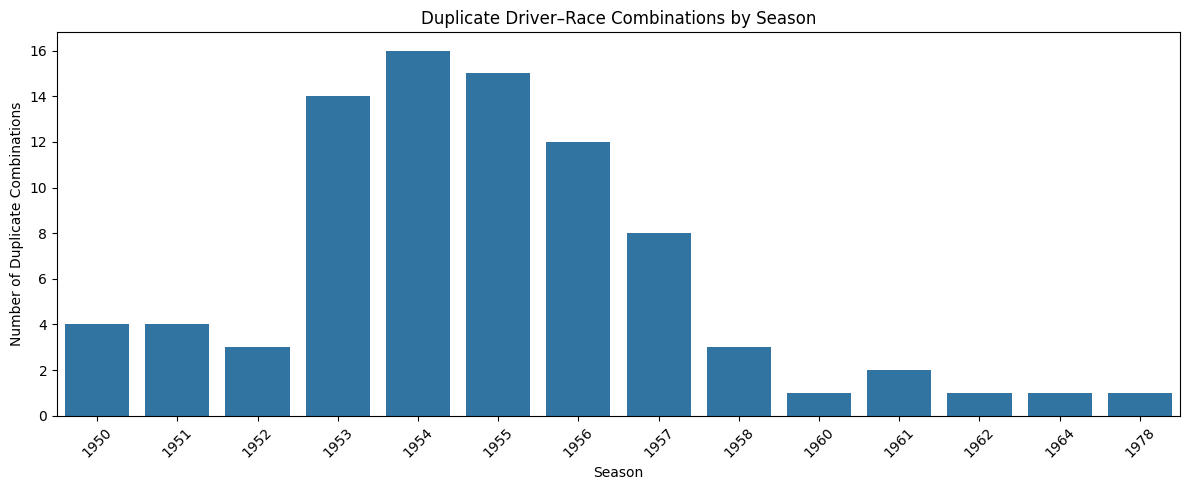

In [42]:

### Duplicate Driver–Race Analysis
# The `results` table contains 26,759 records but only 26,668 unique driver–race combinations. A total of 85 driver–race combinations appear more than once, resulting in 91 additional records.
# The duplicate records are concentrated primarily in early Formula 1 seasons, consistent with historical shared-drive practices.
# Because the prediction is performed before the race starts, deduplication should avoid selecting records based on their final finishing position. We first investigate the available starting-grid information to assess whether a reproducible selection rule can be applied.


duplicate_years = duplicate_driver_races.merge(
    races[["raceId", "year"]],
    on="raceId",
    how="left"
)

duplicates_by_year = (
    duplicate_years.groupby("year")
    .size()
    .reset_index(name="Duplicate Combinations")
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=duplicates_by_year,
    x="year",
    y="Duplicate Combinations"
)

plt.title("Duplicate Driver–Race Combinations by Season")
plt.xlabel("Season")
plt.ylabel("Number of Duplicate Combinations")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [43]:
# Additional Check to investigate:
# More than two records: Some drivers may appear in several records for one race.
# Multiple positive grid positions: Selecting the smallest grid does not necessarily identify which car the driver originally drove.
# Conflicting podium labels: The choice of record could change whether the driver is labeled as a podium finisher.

# Examine the structure of duplicate groups

duplicate_group_audit = (
    duplicate_details
    .groupby(["raceId", "driverId"])
    .agg(
        year=("year", "first"),
        driver=("surname", "first"),
        records=("resultId", "size"),
        positive_grid_entries=("grid", lambda x: (x > 0).sum()),
        zero_grid_entries=("grid", lambda x: (x == 0).sum()),
        distinct_grid_positions=("grid", "nunique"),
        distinct_podium_labels=(
            "positionOrder",
            lambda x: (x <= 3).nunique()
        )
    )
    .reset_index()
)

display(duplicate_group_audit.head(20))

print(
    "Groups with more than two records:",
    (duplicate_group_audit["records"] > 2).sum()
)

print(
    "Groups with multiple positive grid positions:",
    (duplicate_group_audit["positive_grid_entries"] > 1).sum()
)

print(
    "Groups with conflicting podium labels:",
    (duplicate_group_audit["distinct_podium_labels"] > 1).sum()
)


### Duplicate Investigation Findings and Cleaning Strategy
# The investigation identified 85 duplicated driver–race combinations, corresponding to 91 additional records beyond the required one-row-per-driver-race structure.
# Of these duplicated groups, six contain more than two records, while 82 contain multiple positive starting-grid positions. Additionally, 21 groups contain conflicting podium labels, meaning that different records for the same driver and race may indicate different finishing outcomes.
# These findings are consistent with historical Formula 1 shared-drive practices and demonstrate why simple deduplication is insufficient without a documented selection rule.
# For the modeling table, a deterministic grid-based selection strategy is adopted. Records with positive grid positions are prioritized, followed by the smallest positive grid position and then the smallest resultId in case of ties.
# This strategy avoids selecting records based directly on post-race finishing performance. Nevertheless, it is a practical approximation and may not always recover the driver's original car or overall official classification. The resulting historical label uncertainty is acknowledged as a limitation.


,raceId,driverId,year,driver,records,positive_grid_entries,zero_grid_entries,distinct_grid_positions,distinct_podium_labels
0,540,229,1978,Ertl,2,0,2,1,1
1,717,373,1964,Clark,2,2,0,1,1
2,733,465,1962,Greene,2,0,2,1,1
3,742,475,1961,Moss,2,2,0,2,1
4,745,418,1961,Gregory,2,2,0,2,1
5,746,475,1960,Moss,2,2,0,2,2
6,766,541,1958,Flockhart,2,0,2,1,1
7,770,479,1958,Brooks,2,2,0,2,1
8,774,566,1958,Shelby,2,2,0,2,1
9,776,581,1957,Collins,2,2,0,2,1


Groups with more than two records: 6
Groups with multiple positive grid positions: 82
Groups with conflicting podium labels: 21


In [44]:

## Deduplication


# Preserve the original results DataFrame
results_clean = results.copy()

# Prioritize positive grid positions
results_clean["grid_priority"] = (
    results_clean["grid"] <= 0
).astype(int)

# Sort records using our documented selection rule
results_clean = results_clean.sort_values(
    by=[
        "raceId",
        "driverId",
        "grid_priority",
        "grid",
        "resultId"
    ]
)

# Keep one record per driver-race combination
results_clean = results_clean.drop_duplicates(
    subset=["raceId", "driverId"],
    keep="first"
)

# Remove temporary helper column
results_clean = (
    results_clean
    .drop(columns=["grid_priority"])
    .reset_index(drop=True)
)

print("Original rows:", len(results))
print("Cleaned rows:", len(results_clean))
print("Removed rows:", len(results) - len(results_clean))

print(
    "Remaining duplicate driver-race combinations:",
    results_clean.duplicated(
        ["raceId", "driverId"]
    ).sum()
)


Original rows: 26759
Cleaned rows: 26668
Removed rows: 91
Remaining duplicate driver-race combinations: 0


In [45]:

# Compare podium-label counts before and after deduplication

original_podium_count = (
    results["positionOrder"] <= 3
).sum()

cleaned_podium_count = (
    results_clean["positionOrder"] <= 3
).sum()

comparison = pd.DataFrame({
    "Dataset": ["Original", "Deduplicated"],
    "Rows": [len(results), len(results_clean)],
    "Podium Rows": [
        original_podium_count,
        cleaned_podium_count
    ]
})

comparison["Podium Rate (%)"] = (
    comparison["Podium Rows"]
    / comparison["Rows"] * 100
)

display(comparison.round(2))


### Deduplication Results
# The grid-based deduplication strategy reduced the results table from 26,759 to 26,668 records by removing 91 additional driver–race entries.
# After cleaning, no duplicate (`raceId`, `driverId`) combinations remained, satisfying the required modeling-table granularity.
# The number of podium-labeled records decreased from 3,397 to 3,378, while the overall podium rate changed slightly from 12.69% to 12.67%.
# The small change in the overall class distribution suggests that deduplication had a limited aggregate effect on podium frequency. However, 21 duplicated groups originally contained conflicting podium labels, so uncertainty remains for some historical driver–race outcomes.
# The selected grid-based rule is therefore documented as a reproducible approximation rather than a definitive reconstruction of historical shared-drive results.


,Dataset,Rows,Podium Rows,Podium Rate (%)
0,Original,26759,3397,12.69
1,Deduplicated,26668,3378,12.67


In [46]:

## 1.6 Missing-Value Sentinel Handling and Data Type Conversion
# The original CSV files use the literal `\N` to represent missing information.
# During CSV loading, this placeholder was converted into a missing value using Pandas.
# We now verify that no sentinel strings remain, create independent working copies of the datasets, and convert date and lap-time columns into suitable data types.
# These operations preserve the original datasets and avoid modifying raw source files.


# Create independent copies of the original tables
cleaned_datasets = {
    name: df.copy()
    for name, df in datasets.items()
}

# Use the deduplicated results table
cleaned_datasets["results"] = results_clean.copy()

# Check for any remaining literal \N placeholders
sentinel_audit = []

for name, df in cleaned_datasets.items():

    # Check textual columns only
    text_columns = df.select_dtypes(
        include=["object", "string"]
    ).columns

    sentinel_count = (
        df[text_columns]
        .eq("\\N")
        .sum()
        .sum()
    )

    sentinel_audit.append({
        "Table": name,
        "Remaining Sentinels": int(sentinel_count)
    })

    # Replace any remaining sentinels with NaN
    cleaned_datasets[name] = df.replace(
        "\\N", np.nan
    )

sentinel_audit_df = pd.DataFrame(sentinel_audit)

display(sentinel_audit_df)


,Table,Remaining Sentinels
0,circuits,0
1,constructors,0
2,constructor_results,0
3,constructor_standings,0
4,drivers,0
5,driver_standings,0
6,races,0
7,results,0
8,qualifying,0
9,lap_times,0


In [47]:

# Convert date columns to datetime

date_columns = {
    "drivers": ["dob"],
    "races": [
        "date",
        "fp1_date",
        "fp2_date",
        "fp3_date",
        "quali_date",
        "sprint_date"
    ]
}

for table_name, columns in date_columns.items():
    for column in columns:
        cleaned_datasets[table_name][column] = pd.to_datetime(
            cleaned_datasets[table_name][column],
            errors="coerce"
        )

# Verify converted data types
print("Driver date of birth:")
print(cleaned_datasets["drivers"]["dob"].dtype)

print("\nRace date:")
print(cleaned_datasets["races"]["date"].dtype)


### Sentinel Handling and Date Conversion Findings
# The sentinel audit confirmed that all 14 tables contained zero remaining literal `\N` placeholders after loading. This indicates that the initial CSV-loading procedure successfully converted these placeholders into Pandas missing values.
# Date-related columns were subsequently converted from strings into datetime representations using `pd.to_datetime()`.
# Validation confirmed that the driver date-of-birth (`dob`) and race date (`date`) columns now use the `datetime64[ns]` datatype.
# All transformations were performed on independent DataFrame copies to preserve the original data. Additional validation is performed to determine whether date parsing introduced any new missing values.


Driver date of birth:
datetime64[ns]

Race date:
datetime64[ns]


In [48]:

## 1.7 Time Conversion and Semantic Typing
# Lap-time values are originally stored as strings representing minutes and seconds.
# To enable numerical analysis, qualifying times and recorded lap durations are converted into seconds.
# The conversion preserves missing values and handles parsing failures explicitly. New numeric columns are created so that the original string representations remain available for comparison.


# Convert lap-time strings to numeric seconds

def lap_time_to_seconds(value):
    if pd.isna(value):
        return np.nan

    try:
        parts = str(value).split(":")

        if len(parts) == 2:
            minutes = float(parts[0])
            seconds = float(parts[1])

            return minutes * 60 + seconds

        return np.nan

    except (ValueError, TypeError):
        return np.nan


In [49]:

# Convert qualifying lap times

for column in ["q1", "q2", "q3"]:
    cleaned_datasets["qualifying"][column + "_seconds"] = (
        cleaned_datasets["qualifying"][column]
        .apply(lap_time_to_seconds)
    )

# Convert lap_times duration in milliseconds to seconds

cleaned_datasets["lap_times"]["lap_time_seconds"] = (
    pd.to_numeric(
        cleaned_datasets["lap_times"]["milliseconds"],
        errors="coerce"
    ) / 1000
)

# Convert pit stop duration in milliseconds to seconds

cleaned_datasets["pit_stops"]["duration_seconds"] = (
    pd.to_numeric(
        cleaned_datasets["pit_stops"]["milliseconds"],
        errors="coerce"
    ) / 1000
)

# Display example conversions

display(
    cleaned_datasets["qualifying"][
        ["q1", "q1_seconds", "q2", "q2_seconds", "q3", "q3_seconds"]
    ].head(10)
)

display(
    cleaned_datasets["lap_times"][
        ["time", "milliseconds", "lap_time_seconds"]
    ].head(5)
)


,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236
5,1:26.427,86.427,1:26.101,86.101,1:28.527,88.527
6,1:26.295,86.295,1:26.059,86.059,1:28.687,88.687
7,1:26.381,86.381,1:26.063,86.063,1:29.041,89.041
8,1:26.919,86.919,1:26.164,86.164,1:29.593,89.593
9,1:26.702,86.702,1:25.842,85.842,NaN,NaN


,time,milliseconds,lap_time_seconds
0,1:38.109,98109,98.109
1,1:33.006,93006,93.006
2,1:32.713,92713,92.713
3,1:32.803,92803,92.803
4,1:32.342,92342,92.342


In [50]:

# Check conversion results

conversion_audit = []

for column in ["q1", "q2", "q3"]:
    original = cleaned_datasets["qualifying"][column]
    converted = cleaned_datasets["qualifying"][column + "_seconds"]

    conversion_audit.append({
        "Column": column,
        "Original Non-Null": original.notna().sum(),
        "Converted Non-Null": converted.notna().sum(),
        "New Parsing Failures": (
            original.notna() & converted.isna()
        ).sum()
    })

display(pd.DataFrame(conversion_audit))

# Check whether date parsing introduced missing values

date_audit = []

for table_name, columns in date_columns.items():
    for column in columns:
        before = datasets[table_name][column]
        after = cleaned_datasets[table_name][column]

        date_audit.append({
            "Table": table_name,
            "Column": column,
            "Before Missing": before.isna().sum(),
            "After Missing": after.isna().sum(),
            "New Missing": (
                before.notna() & after.isna()
            ).sum()
        })

display(pd.DataFrame(date_audit))


### Semantic Data Type Conversion: Findings
# Qualifying lap times were converted from minute-second strings into numeric seconds to support subsequent statistical analysis.
# The conversion was successful for all available qualifying records. Specifically, 10,338 Q1 times, 5,847 Q2 times, and 3,629 Q3 times were converted without introducing any additional missing values.
# Recorded lap durations and pit-stop durations were also converted from milliseconds into seconds.
# Date-related attributes were converted into datetime representations. Validation showed that these conversions introduced no additional missing values.
# The original string representations were preserved, while new numeric columns were created for time-based analysis.
# The differences in Q1, Q2, and Q3 availability should not automatically be treated as data-quality errors because qualifying participation varies between sessions and historical formats.
# These transformations improve data consistency while preserving the original information and existing missing-value patterns.


,Column,Original Non-Null,Converted Non-Null,New Parsing Failures
0,q1,10338,10338,0
1,q2,5847,5847,0
2,q3,3629,3629,0


,Table,Column,Before Missing,After Missing,New Missing
0,drivers,dob,0,0,0
1,races,date,0,0,0
2,races,fp1_date,1035,1035,0
3,races,fp2_date,1035,1035,0
4,races,fp3_date,1053,1053,0
5,races,quali_date,1035,1035,0
6,races,sprint_date,1107,1107,0


In [51]:

## 1.8 Post-Cleaning Exploratory Data Analysis
# After performing deduplication, missing-value handling, and semantic datatype conversion, we compare the original and cleaned datasets.
# The objective is to quantify the impact of preprocessing on dataset size, missingness, and the distribution of the podium prediction target.
# We also validate that the cleaned results table satisfies the required one-row-per-driver-race structure.


# Compare row counts before and after cleaning

cleaning_comparison = []

for name in datasets:

    original_df = datasets[name]
    cleaned_df = cleaned_datasets[name]

    cleaning_comparison.append({
        "Table": name,
        "Original Rows": len(original_df),
        "Cleaned Rows": len(cleaned_df),
        "Rows Removed": len(original_df) - len(cleaned_df),
        "Original Missing": int(original_df.isna().sum().sum()),
        "Cleaned Missing": int(
            cleaned_df[
                original_df.columns
            ].isna().sum().sum()
        )
    })

cleaning_comparison_df = pd.DataFrame(cleaning_comparison)

display(cleaning_comparison_df)


,Table,Original Rows,Cleaned Rows,Rows Removed,Original Missing,Cleaned Missing
0,circuits,77,77,0,0,0
1,constructors,212,212,0,0,0
2,constructor_results,12625,12625,0,12608,12608
3,constructor_standings,13391,13391,0,0,0
4,drivers,861,861,0,1559,1559
5,driver_standings,34863,34863,0,0,0
6,races,1125,1125,0,11349,11349
7,results,26759,26668,91,122887,122332
8,qualifying,10494,10494,0,11668,11668
9,lap_times,589081,589081,0,0,0


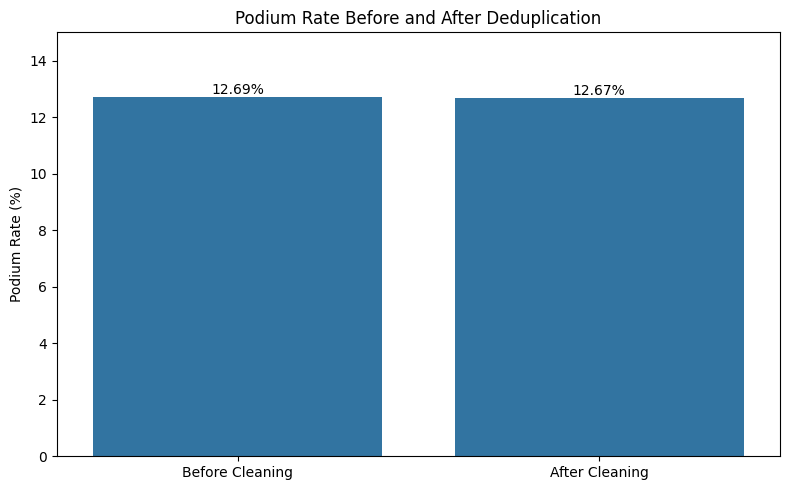

,Dataset,Podium Rate (%)
0,Before Cleaning,12.695
1,After Cleaning,12.667


In [52]:

# Compare podium rates before and after cleaning

podium_comparison = pd.DataFrame({
    "Dataset": ["Before Cleaning", "After Cleaning"],
    "Podium Rate (%)": [
        (results["positionOrder"] <= 3).mean() * 100,
        (
            cleaned_datasets["results"]["positionOrder"] <= 3
        ).mean() * 100
    ]
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=podium_comparison,
    x="Dataset",
    y="Podium Rate (%)"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Podium Rate Before and After Deduplication")
plt.ylabel("Podium Rate (%)")
plt.xlabel("")

plt.ylim(0, 15)
plt.tight_layout()
plt.show()

display(podium_comparison.round(3))


In [53]:

# Final validation of cleaned results

final_results = cleaned_datasets["results"]

assert final_results.duplicated(
    ["raceId", "driverId"]
).sum() == 0, "Duplicate driver-race combinations remain."

assert final_results["raceId"].notna().all(), \
    "Missing race identifiers detected."

assert final_results["driverId"].notna().all(), \
    "Missing driver identifiers detected."

assert final_results["positionOrder"].notna().all(), \
    "Missing target values detected."

assert len(final_results) == 26668, \
    "Unexpected number of records after cleaning."

print("All final validation checks passed.")
print("Cleaned records:", len(final_results))
print(
    "Unique driver-race combinations:",
    final_results[["raceId", "driverId"]]
    .drop_duplicates().shape[0]
)


## 1.9 EDA and Data Cleaning Summary
# The initial exploratory analysis examined 14 relational Formula 1 tables and identified considerable differences in dataset size, completeness, and historical coverage.
# Missing-value analysis revealed that the races, results, drivers, constructor_results, and qualifying tables contained substantial missing information. Historical qualifying analysis further demonstrated that qualifying record coverage varies significantly across seasons, becoming approximately complete from 2003 onward.
# Primary-key validation found no null or duplicate candidate keys across the 14 tables. Foreign-key auditing also confirmed that all 22 tested relationships contained valid, non-null references.
# The results table initially contained 26,759 records but only 26,668 unique driver–race combinations. A total of 91 extra records were removed using a documented grid-based selection rule. This produced a table with exactly one record per driver–race combination.
# Deduplication reduced the podium rate slightly from 12.695% to 12.667%. However, some historical shared-drive entries had conflicting podium labels, meaning that the selected outcomes should be interpreted with caution.
# Missing-value sentinels were standardized, dates were converted to datetime representations, and qualifying lap times and recorded durations were converted into numeric seconds. Validation confirmed that these conversions introduced no additional missing values in the tested date and qualifying-time columns.
# Post-cleaning checks confirmed that the cleaned results table contains 26,668 unique driver–race records with no remaining duplicate combinations.
# The cleaned tables provide a consistent foundation for subsequent relational analysis and feature engineering. Nevertheless, historical data limitations, missing measurements, and uncertainty in shared-drive records must be considered during downstream modeling.


All final validation checks passed.
Cleaned records: 26668
Unique driver-race combinations: 26668


In [54]:

# Verify that the cleaned tables are available
# for the next stage of the project.

print("Cleaned tables:", len(cleaned_datasets))

print(
    "Cleaned results shape:",
    cleaned_datasets["results"].shape
)

print(
    "Qualifying columns:",
    cleaned_datasets["qualifying"].columns.tolist()
)

print(
    "Duplicate driver-race entries:",
    cleaned_datasets["results"]
    .duplicated(["raceId", "driverId"])
    .sum()
)


Cleaned tables: 14
Cleaned results shape: (26668, 18)
Qualifying columns: ['qualifyId', 'raceId', 'driverId', 'constructorId', 'number', 'position', 'q1', 'q2', 'q3', 'q1_seconds', 'q2_seconds', 'q3_seconds']
Duplicate driver-race entries: 0


In [55]:
# Prepare cleaned datasets for Member 2
results_clean = cleaned_datasets["results"]
qualifying_clean = cleaned_datasets["qualifying"]
races_clean = cleaned_datasets["races"]